<a href="https://colab.research.google.com/github/batu-uchicago/bayes-applications/blob/main/Bayesian%20Inference/map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Five hypotheses about a coin

A coin's chance of heads, θ, is one of five values, and each value is a hypothesis.
Before any flips we believe the middle one most:

| Hypothesis | h1 | h2 | h3 | h4 | h5 |
|---|---|---|---|---|---|
| θ = P(heads) | 0 | 0.25 | 0.5 | 0.75 | 1 |
| Prior P(h) | 0.1 | 0.2 | 0.4 | 0.2 | 0.1 |

We flip a coin that really follows h2 twenty times and update our belief in every hypothesis after each flip.
The hypothesis with the largest posterior is the MAP (maximum a posteriori) estimate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

thetas = np.array([0.0, 0.25, 0.5, 0.75, 1.0])  # P(heads) under h1, ..., h5
prior = np.array([0.1, 0.2, 0.4, 0.2, 0.1])
TRUE_THETA = 0.25  # the coin follows h2
N_FLIPS = 20

# Seeded so every run shows the same flips. Seed 146 spreads the 5 heads evenly,
# so the posterior moves from the prior's favourite, h3, to h2 without detours.
rng = np.random.default_rng(146)
flips = rng.binomial(1, TRUE_THETA, N_FLIPS)  # 1 is heads
print("Flips:", " ".join("H" if f else "T" for f in flips))

Flips: H T T T H T T T T T H T T T H T T T T H


## Updating after every flip

After $n$ flips with $k$ heads, the likelihood of a hypothesis is $\theta^k (1-\theta)^{n-k}$.
Multiplying by the prior and dividing by the total gives the posterior:

$$P(h \mid \text{data}) = \frac{P(\text{data} \mid h)\, P(h)}{\sum_{h'} P(\text{data} \mid h')\, P(h')}$$

One head rules out h1 for good, and one tail rules out h5.

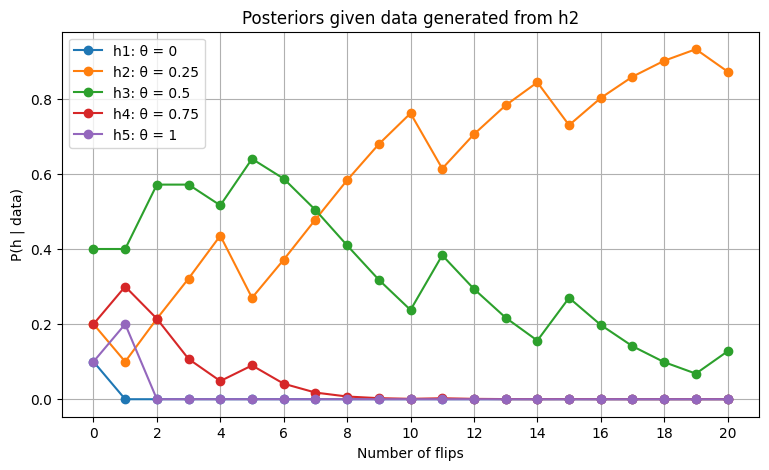

In [2]:
n = np.arange(N_FLIPS + 1)  # 0 flips (the prior), 1 flip, ..., 20 flips
heads = np.concatenate([[0], np.cumsum(flips)])

likelihood = thetas ** heads[:, None] * (1 - thetas) ** (n - heads)[:, None]
posterior = prior * likelihood
posterior /= posterior.sum(axis=1, keepdims=True)  # row i: the posterior after i flips

fig, ax = plt.subplots(figsize=(9, 5))
for j, theta in enumerate(thetas):
    ax.plot(n, posterior[:, j], marker="o", label=f"h{j + 1}: θ = {theta:g}")
ax.set_title("Posteriors given data generated from h2")
ax.set_xlabel("Number of flips")
ax.set_ylabel("P(h | data)")
ax.set_xticks(n[::2])
ax.grid(True)
ax.legend()
plt.show()

## The MAP hypothesis

MAP keeps only the most probable hypothesis.
At first the prior decides, so MAP is h3. As the tails pile up, h2 takes over.

In [3]:
map_h = posterior.argmax(axis=1)
print("flips  heads  MAP  P(MAP | data)")
for i in n:
    print(f"{i:5d}  {heads[i]:5d}  h{map_h[i] + 1}   {posterior[i, map_h[i]]:.2f}")

flips  heads  MAP  P(MAP | data)
    0      0  h3   0.40
    1      1  h3   0.40
    2      1  h3   0.57
    3      1  h3   0.57
    4      1  h3   0.52
    5      2  h3   0.64
    6      2  h3   0.59
    7      2  h3   0.50
    8      2  h2   0.58
    9      2  h2   0.68
   10      2  h2   0.76
   11      3  h2   0.61
   12      3  h2   0.71
   13      3  h2   0.78
   14      3  h2   0.84
   15      4  h2   0.73
   16      4  h2   0.80
   17      4  h2   0.86
   18      4  h2   0.90
   19      4  h2   0.93
   20      5  h2   0.87


## Try it

Change `TRUE_THETA`, the prior or the seed, then rerun the notebook.
With a flatter prior, how many flips does the data need before MAP settles on the true hypothesis?